#### Load Packages

In [ ]:
suppressMessages(library(tidyverse))  
suppressMessages(library(pheatmap))
suppressMessages(library(pROC))

options(stringsAsFactors = FALSE)

source("./Manuscript_files/theme_ggplot_cfrna.R")
source("./Manuscript_files/DAA_scripts.R")

In [33]:
# READ IN FILES
res <- read.csv("./Manuscript_files/deseq2_res.csv", row.names = 1)
counts_vst <- read.csv("./Manuscript_files/counts_vst_output.csv", row.names = 1)
samples <- read.delim("./Manuscript_files/sample_metadata.tsv")
gene.list <- read.delim("./Manuscript_files/gencode.biotype.name.key.tsv")

In [3]:
res %>% data.frame() %>% arrange(pvalue) %>% filter(padj < 0.05, abs(log2FoldChange) > 0.5) %>% nrow()
res %>% data.frame() %>% arrange(pvalue) %>% filter(padj < 0.05, log2FoldChange > 0.5) %>% nrow()
res %>% data.frame() %>% arrange(pvalue) %>% filter(padj < 0.05, log2FoldChange < -0.5) %>% nrow()

[1] 743

[1] 608

[1] 135

#### Plotting Code: Outputs from DESeq2

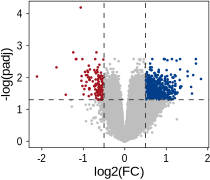

In [4]:
# VOLCANO PLOT
width = 1.75
height = 1.5
options(repr.plot.width = width, repr.plot.height = height)

detable = res %>% data.frame %>%
    filter(!is.na(padj)) %>% 
    mutate(sig_dir = ifelse(padj<0.05 & log2FoldChange>0.5,"up", ifelse(padj<0.05 & log2FoldChange < -0.5,"down","notsig")))

plot_name = "daa_vol_plot"

plot_me <- detable %>%
    ggplot(aes(x=log2FoldChange, y=-log10(padj), color = sig_dir)) + 
    geom_point(size = 0.1) +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color="gray20", linewidth = 0.25) +
    geom_vline(xintercept = c(-0.5, 0.5), linetype = "dashed", color="gray20", linewidth = 0.25) +
    theme_cfrna_paper() + 
    labs(x = "log2(FC)", y = "-log(padj)", title = NULL) +
    scale_color_manual(values = c("notsig"="grey","down"="#a31621","up"="#023E8A")) 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [5]:
# HEATMAP
width = 4
height = 5
options(repr.plot.width = width, repr.plot.height = height)

plot_name = "daa_heatmap"

mycolors <- list(
    phenotype = c("MECFS" = "#023E8A", "HC" = "#a31621"), 
    sex = c("F" = "#ea9ab2", "M" = "#1b9aaa"),
    test_site = c("ITH" = '#8cb369', "NYC" = '#7678ed', "LA" = '#f7b801')
    )
vars = c("phenotype", "sex", "test_site")

# Save the plot as a PDF
pdf(paste0("/workdir/aeg267/ME_CFS/02_Scripts/Figure_outputs/figure_2/", plot_name, ".pdf"), width = width, height = height)

plot_me <- make_heatmap(res, counts_vst, samples, "sample_id_0", mycolors, vars, 
                      SIG_THRESH = 0.05, FC_THRESH = 0.75, BM_THRESH = 0)    

dev.off()

plot_me

pdf 
  3

#### Plotting Code: Outputs from ML 

In [6]:
ml_outputs_all <- read.delim("/workdir/aeg267/ME_CFS/02_Scripts/Manuscript_files/ml_outputs_all.tsv")

In [7]:
# Calculate the average train AUC for each model
average_train_auc <- ml_outputs_all %>%
  filter(method == "train") %>%  
  group_by(model) %>%            
  summarize(avg_train_auc = round(mean(auc), 3)) # Calculate average AUC

# Calculate the average test AUC for each model
average_test_auc <- ml_outputs_all %>%
  filter(method == "test") %>%  
  group_by(model) %>%           
  summarize(avg_test_auc = round(mean(auc), 3)) 

# Calculate the top test AUC for each model
top_test_auc <- ml_outputs_all %>%
  filter(method == "test") %>% 
  group_by(model) %>% 
  summarize(top_test_auc = round(max(auc), 3))

# Calculate the top test AUC for each model
top_train_auc <- ml_outputs_all %>%
  filter(method == "train") %>% 
  group_by(model) %>% 
  summarize(top_train_auc = round(max(auc), 3))

# Merge average auc based on the model
average_auc <- merge(average_train_auc, average_test_auc, by = "model")
average_auc <- merge(average_auc, top_test_auc, by = "model")
average_auc <- merge(average_auc, top_train_auc, by = "model")

average_auc %>% arrange(desc(avg_test_auc))

model,avg_train_auc,avg_test_auc,top_test_auc,top_train_auc
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
NB,0.776,0.650,0.776,0.920
GLMNETRidge,0.848,0.645,0.789,0.966
SVMLIN,0.894,0.641,0.765,1.000
PAM,0.740,0.634,0.761,0.790
EXTRATREES,1.000,0.633,0.777,1.000
NNET,0.931,0.627,0.821,1.000
RF,1.000,0.626,0.748,1.000
GLMNETLasso,0.895,0.625,0.810,1.000
SVMRAD,0.926,0.621,0.748,1.000


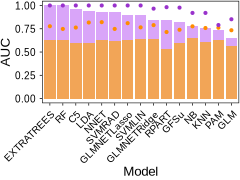

In [8]:
# AVERAGE AND TOP AUC
width = 2
height = 1.5
options(repr.plot.width = width, repr.plot.height = height)

plot_name = "model_avgs"

plot_me <- ggplot(average_auc, aes(x = reorder(model, -avg_train_auc))) +
    geom_bar(aes(y = avg_train_auc), stat = "identity", fill = "purple", alpha = 0.4) +
    geom_bar(aes(y = avg_test_auc), stat = "identity", fill = "orange", alpha = 0.65) +
    geom_point(aes(y = top_test_auc), color = "darkorange", size = 0.5) +
    geom_point(aes(y = top_train_auc), color = "darkorchid", size = 0.5) +
    labs(title = NULL, x = "Model", y = "AUC") +
    theme_cfrna_paper() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [9]:
counts_meta_test <- read.delim("/workdir/aeg267/ME_CFS/02_Scripts/Manuscript_files/counts_meta_test.tsv")

counts_meta_test <- counts_meta_test %>%
    mutate(total_test_norm = total_test / max(total_test))

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


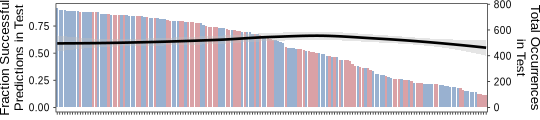

In [10]:
# FRACTION SUCCESSFUL PREDICTIONS IN TEST SETS BY SAMPLE
width = 4.5
height = 1
options(repr.plot.width = width, repr.plot.height = height)

plot_name = "fraction_success_test"

plot_me <- ggplot(counts_meta_test, aes(x = reorder(sample_id, -pct_correct_test), fill = phenotype)) +
    geom_bar(aes(y = pct_correct_test), stat = "identity", alpha = 0.4) +
    geom_smooth(aes(y = total_test_norm, group = 1), method = "loess", color = "black", linewidth = 0.75, se = TRUE, fill = "gray") + 
    scale_y_continuous(name = "Fraction Successful\nPredictions in Test",
        sec.axis = sec_axis(~ . * max(counts_meta_test$total_test), name = "Total Occurrences\nin Test")) + 
    scale_fill_manual(values = COLORS) +
    theme_cfrna_paper() +
    labs(title = NULL, x = NULL) +
    theme(
        axis.text.x = element_text(size = 0), # remove x-axis labels
        axis.title.y.right = element_text(color = "black"), plot.margin = margin(t = 2))

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

#### Plotting Code: Select Optimal Model

In [11]:
counts_train_norm = read.delim("./Manuscript_files/GLMNETLasso/seed_22_all.counts.train.VST.tsv")
counts_test_norm = read.delim("./Manuscript_files/GLMNETLasso/seed_22_all.counts.test.VST.tsv")

deseq = read.delim("./Manuscript_files/GLMNETLasso/seed_22_all.deseqResults.tsv")

metadata_test = read.delim("./Manuscript_files/GLMNETLasso/seed_22_all.metadata.test.tsv")
metadata_train = read.delim("./Manuscript_files/GLMNETLasso/seed_22_all.metadata.train.tsv")
metadata_all = rbind(metadata_train, metadata_test)

rds_file = readRDS("./Manuscript_files/GLMNETLasso/seed_22_all.GLMNETLasso.rds")
output_test = read.delim("./Manuscript_files/GLMNETLasso/seed_22_all.GLMNETLasso.test.txt")
output_train = read.delim("./Manuscript_files/GLMNETLasso/seed_22_all.GLMNETLasso.train.txt")

In [12]:
## Wrangle data into Plot Friendly Format
#Train data
norm_plot_dat_train = counts_train_norm %>% t() %>%
    as.data.frame() %>% 
    tibble::rownames_to_column(., var = "gene_id") %>%
    gather(sample_id, value, -gene_id) %>%
    spread(gene_id, value)

norm_plot_dat_train = merge(norm_plot_dat_train, metadata_train, by.x = "sample_id")

#Test data
norm_plot_dat_test = counts_test_norm %>% t() %>%
    as.data.frame() %>% 
    tibble::rownames_to_column(., var = "gene_id") %>%
    gather(sample_id, value, -gene_id) %>%
    spread(gene_id, value)

norm_plot_dat_test = merge(norm_plot_dat_test, metadata_test, by.x = "sample_id")

#Merge all for later figures
norm_plot_dat_all = rbind(norm_plot_dat_train, norm_plot_dat_test)

deseq$gene_num = rownames(deseq)


In [13]:
gene_names <- as.character(deseq$gene_num)

# TRAIN: Set the predicted probabilities
df_train = norm_plot_dat_train
df_train$phenotype <- ifelse(df_train$phenotype == "MECFS", 1, 0)
df_train$phenotype <- as.factor(df_train$phenotype)
temp_train = rds_file$meta_data_train
temp_train$predicted_probs = 1 - temp_train$classifier_score # Must invert classifier score 
temp_train = temp_train %>% select(sample_id, predicted_probs)
df_train = left_join(df_train, temp_train, by = "sample_id")

# TEST: Set the predicted probabilities
df_test = norm_plot_dat_test
df_test$phenotype <- ifelse(df_test$phenotype == "MECFS", 1, 0)
df_test$phenotype <- as.factor(df_test$phenotype)
temp_test = rds_file$meta_data_test
temp_test$predicted_probs = 1 - temp_test$classifier_score # Must invert classifier score 
temp_test = temp_test %>% select(sample_id, predicted_probs)
df_test = left_join(df_test, temp_test, by = "sample_id")

# Assign labels for each dataframe
df_train$type <- "Train"
df_test$type <- "Test"

# Combine the dataframes for plotting
combined_df <- rbind(df_train, df_test)
combined_df$type <- factor(combined_df$type, levels = c("Train", "Test"))

In [14]:
# Calculate TRAINING ROC and AUC
roc_train <- roc(df_train$phenotype, df_train$predicted_probs)
auc_train <- auc(roc_train)
roc_train_ci = ci.auc(roc_train)

print(paste0("Training ROC-AUC: ", round(auc(roc_train),3)))
print(paste0("Training ROC-AUC 95% CI: [", round(roc_train_ci[1],3), "--", round(roc_train_ci[3],3), "]"))

# Calculate TEST ROC and AUC
roc_test <- roc(df_test$phenotype, df_test$predicted_probs)
auc_test <- auc(roc_test)
roc_test_ci = ci.auc(roc_test)

print(paste0("Test ROC-AUC: ", round(auc(roc_test),3)))
print(paste0("Test ROC-AUC 95% CI: [", round(roc_test_ci[1],3), "--", round(roc_test_ci[3],3), "]"))


Setting levels: control = 0, case = 1

Setting direction: controls < cases



[1] "Training ROC-AUC: 0.86"
[1] "Training ROC-AUC 95% CI: [0.789--0.932]"


Setting levels: control = 0, case = 1

Setting direction: controls < cases



[1] "Test ROC-AUC: 0.81"
[1] "Test ROC-AUC 95% CI: [0.694--0.926]"


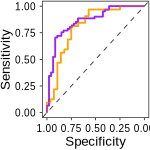

In [15]:
# AUC ROC 
width = 1.25
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

plot_name = "roc"

plot_me <- ggroc(list("Test" = roc_test, "Train"= roc_train), aes=c("color"))  +
    theme_cfrna_paper() +
    geom_line(lwd = .25, alpha = 1) + 
    scale_color_manual(values=c("orange", "purple")) +
    labs(y = "Sensitivity", x = "Specificity", title = NULL) +
    geom_abline(slope = 1, intercept = 1, linetype = "dashed", color = "gray20", lwd = 0.25) 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

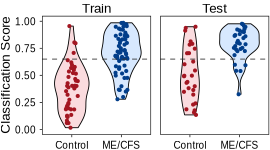

In [16]:
# TRAIN TEST CLASSICIFICATION 
width = 2.25
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

plot_name = "model_performance"

set.seed(3.14)

plot_me <- ggplot(combined_df, aes(x = phenotype, y = predicted_probs, fill = phenotype)) +
      geom_violin(trim = TRUE, width = 0.8, lwd = 0.25, color = "black") +
      geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.5, jitter.height = 0), alpha = 1, size = 0.5) +
      geom_hline(yintercept = 0.65, linetype = "dashed", color="gray20", linewidth = 0.25) +
      scale_fill_manual(values = COLORS_FILL) +
      scale_color_manual(values = COLORS) +
      scale_x_discrete(labels = c(`0` = "Control", `1` = "ME/CFS")) +
      theme_cfrna_paper() +
      facet_wrap(~ type, ncol = 2, scales = "free_x") + 
      theme(strip.background = element_blank(), strip.text = element_text(margin = margin(t = 1, b = 1))) + 
      ylim(0,1) +
      labs(y = "Classification Score", x = NULL, title = NULL) 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

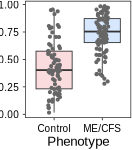

In [17]:
# PHENOTYPE VS SCORE 
width = 1.1
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

plot_name = "pheno_vs_score"

plot_me <- ggplot(combined_df, aes(x = phenotype, y = predicted_probs, fill = phenotype)) +
    geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
    geom_jitter(position = position_jitterdodge(jitter.width = 0.5), alpha = 1, size = 0.5, color = "gray40") +
    scale_fill_manual(values = COLORS_FILL) +
    theme_cfrna_paper() +
    scale_x_discrete(labels = c("1" = "ME/CFS", "0" = "Control")) +
    labs(title = NULL, x = "Phenotype", y = NULL) 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

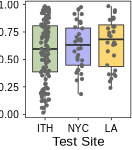

In [18]:
# TEST SITE VS SCORE 
plot_name = "testsite_vs_score"

plot_me <- ggplot(combined_df, aes(x = test_site, y = predicted_probs, fill = test_site, alpha = 0.09)) +
    geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
    geom_jitter(position = position_jitterdodge(jitter.width = 0.25), alpha = 1, size = 0.5, color = "gray40") +
    scale_fill_manual(values = c("ITH" = '#8cb369', "NYC" = '#7678ed', "LA" = '#f7b801')) +
    theme_cfrna_paper() +
    scale_x_discrete(limits = c("ITH", "NYC", "LA")) +
    labs(title = NULL, x = "Test Site", y = NULL) 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

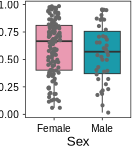

In [19]:
# SEX VS SCORE 
plot_name = "sex_vs_score"

plot_me <- ggplot(combined_df, aes(x = sex, y = predicted_probs, fill = sex)) +
    geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
    geom_jitter(position = position_jitterdodge(jitter.width = 0.25), alpha = 1, size = 0.5, color = "gray40") +
    scale_fill_manual(values =  c("F" = "#ea9ab2", "M" = "#1b9aaa"))+
    theme_cfrna_paper() +
    scale_x_discrete(labels = c("F" = "Female", "M" = "Male")) +
    labs(title = NULL, x = "Sex", y = NULL) 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [20]:
combined_df$GH <- as.numeric(combined_df$GH)

Warning message in eval(expr, envir, enclos):
“NAs introduced by coercion”


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 12 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 12 rows containing missing values or values outside the scale range
(`geom_point()`).”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 12 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 12 rows containing missing values or values outside the scale range
(`geom_point()`).”


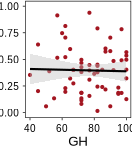

In [21]:
# GH VS CLASSIFICATION SCORE: CONTROLS
plot_name = "HC_GH_vs_score"

plot_me <- ggplot(combined_df %>% filter(phenotype == "0"), aes(x = GH, y = predicted_probs)) +
    geom_point(color = "#a31621", size = 0.5) +
    geom_smooth(method = "lm", se = TRUE, fill = "gray", color = "black", lwd = .6) + 
    labs(x = "GH", y = NULL) +
    ylim(0, 1) +
    theme_cfrna_paper() 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


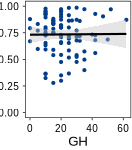

In [22]:
# GH VS CLASSIFICATION SCORE: CASES
plot_name = "ME_GH_vs_score"

plot_me <- ggplot(combined_df %>% filter(phenotype == "1"), aes(x = GH, y = predicted_probs)) +
    geom_point(color = "#023E8A", size = 0.5) +
    geom_smooth(method = "lm", se = TRUE, fill = "gray", color = "black", lwd = .6) + 
    labs(x = "GH", y = NULL) +
    ylim(0, 1) +
    theme_cfrna_paper() 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height) 

Warning message in eval(expr, envir, enclos):
“NAs introduced by coercion”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 33 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 33 rows containing missing values or values outside the scale range
(`geom_point()`).”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 33 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 33 rows containing missing values or values outside the scale range
(`geom_point()`).”


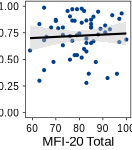

In [23]:
# MFI-20 VS CLASSIFICATION SCORE: CASES
combined_df$mfi20_total <- as.numeric(combined_df$mfi20_total)

plot_name = "ME_mfi20_vs_score"

plot_me <- ggplot(combined_df %>% filter(phenotype == "1"), aes(x = mfi20_total, y = predicted_probs)) +
    geom_point(color = "#023E8A", size = 0.5) +
    geom_smooth(method = "lm", se = TRUE, fill = "gray", color = "black", lwd = .6) + 
    labs(x = "MFI-20 Total", y = NULL) +
    ylim(0, 1) +
    theme_cfrna_paper() 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

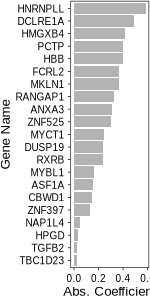

In [24]:
# GENE COEFFICIENTS FROM GLMNET LASSO
final_model <- rds_file

# Extract the best lambda from the model
best_lambda <- final_model$model$bestTune$lambda

# Get all coefficients at the best lambda
coefs <- coef(final_model$model$finalModel, s = best_lambda)
coefs <- as.matrix(coefs)

# Filter out zero coefficients and the intercept
non_zero_coefs <- coefs[coefs != 0, , drop = FALSE]
non_zero_coefs <- non_zero_coefs[rownames(non_zero_coefs) != "(Intercept)", , drop = FALSE]

# Build dataframe with gene IDs and coefficients
ranked_genes_df <- data.frame(
  GeneID = rownames(non_zero_coefs),
  Coefficient = non_zero_coefs[, 1],
  stringsAsFactors = FALSE
)

# Merge with gene.list to get gene names
ranked_genes_df <- ranked_genes_df %>%
  left_join(gene.list, by = c("GeneID" = "gene_id")) %>%
  mutate(Impact = abs(Coefficient)) %>%
  arrange(desc(Impact)) %>%
  select(GeneID, gene_name, Coefficient)

# Plot the top 25 genes by absolute coefficient
top_genes_to_plot <- ranked_genes_df %>% slice_max(order_by = abs(Coefficient), n = 25)

# Plotting
width <- 1.25
height <- 2.5
options(repr.plot.width = width, repr.plot.height = height)

plot_name <- "gene_coefficients"

plot_me <- ggplot(top_genes_to_plot, aes(x = reorder(gene_name, abs(Coefficient)), y = abs(Coefficient))) +
  geom_bar(stat = "identity", fill = "gray70") +
  coord_flip() +
  labs(title = NULL, x = "Gene Name", y = "Abs. Coefficient") +
  theme_cfrna_paper()

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

#### Plotting Code: Shuffle Phenotype Analysis

In [25]:
ml_shuffle_outputs_all <- read.delim("/workdir/aeg267/ME_CFS/02_Scripts/Manuscript_files/ml_shuffle_outputs_all.tsv")

In [26]:
# Calculate the average train AUC for each model
shuffle_average_train_auc <- ml_shuffle_outputs_all %>%
  filter(method == "train") %>%  
  group_by(model) %>%            
  summarize(avg_train_auc = round(mean(auc), 3)) # Calculate average AUC

# Calculate the average test AUC for each model
shuffle_average_test_auc <- ml_shuffle_outputs_all %>%
  filter(method == "test") %>%  
  group_by(model) %>%           
  summarize(avg_test_auc = round(mean(auc), 3)) 

# Calculate the top test AUC for each model
shuffle_top_test_auc <- ml_shuffle_outputs_all %>%
  filter(method == "test") %>% 
  group_by(model) %>% 
  summarize(top_test_auc = round(max(auc), 3))

# Merge average auc based on the model
shuffle_average_auc <- merge(shuffle_average_train_auc, shuffle_average_test_auc, by = "model")
shuffle_average_auc <- merge(shuffle_average_auc, shuffle_top_test_auc, by = "model")

shuffle_average_auc %>% arrange(desc(avg_test_auc))

model,avg_train_auc,avg_test_auc,top_test_auc
<chr>,<dbl>,<dbl>,<dbl>
PAM,0.700,0.557,0.768
RF,1.000,0.557,0.700
EXTRATREES,0.951,0.556,0.745
GLMNETLasso,0.717,0.556,0.734
C5,0.784,0.555,0.689
GLMNETRidge,0.713,0.554,0.750
SVMRAD,0.689,0.552,0.766
NNET,0.790,0.551,0.748
GFSu,0.657,0.550,0.742


In [27]:
average_auc %>% arrange(desc(avg_test_auc))

model,avg_train_auc,avg_test_auc,top_test_auc,top_train_auc
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
NB,0.776,0.650,0.776,0.920
GLMNETRidge,0.848,0.645,0.789,0.966
SVMLIN,0.894,0.641,0.765,1.000
PAM,0.740,0.634,0.761,0.790
EXTRATREES,1.000,0.633,0.777,1.000
NNET,0.931,0.627,0.821,1.000
RF,1.000,0.626,0.748,1.000
GLMNETLasso,0.895,0.625,0.810,1.000
SVMRAD,0.926,0.621,0.748,1.000


In [28]:
merged_data <- merge(average_auc, shuffle_average_auc, by = "model", suffixes = c("_v0", "_v2"))

In [29]:
head(merged_data)

,model,avg_train_auc_v0,avg_test_auc_v0,top_test_auc_v0,top_train_auc,avg_train_auc_v2,avg_test_auc_v2,top_test_auc_v2
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,C5,0.964,0.599,0.763,1.000,0.784,0.555,0.689
2,EXTRATREES,1.000,0.633,0.777,1.000,0.951,0.556,0.745
3,GFSu,0.821,0.595,0.739,0.977,0.657,0.550,0.742
4,GLM,0.656,0.566,0.734,0.852,0.667,0.545,0.735
5,GLMNETLasso,0.895,0.625,0.810,1.000,0.717,0.556,0.734
6,GLMNETRidge,0.848,0.645,0.789,0.966,0.713,0.554,0.750


In [30]:
# Calculate the difference in average test AUC between v0 and v2
merged_data$difference <- merged_data$avg_test_auc_v0 - merged_data$avg_test_auc_v2
merged_data$difference_top <- merged_data$top_test_auc_v0 - merged_data$top_test_auc_v2

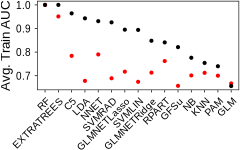

In [31]:
# TRAIN SET: AVG AUC AFTER SHUFFLE PHENOTYPES
width = 2
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

plot_name = "model_train_shuffle_auc"

merged_data <- merged_data %>%
    mutate(model = factor(model, levels = c("RF", setdiff(model, "RF"))))

plot_me <- ggplot(merged_data %>% arrange(-avg_train_auc_v0), aes(x = reorder(model, -avg_train_auc_v0))) + 
    geom_point(aes(y = avg_train_auc_v2, color = "v2"), size = 0.5) +
    geom_point(aes(y = avg_train_auc_v0, color = "v0"), size = 0.5) +
    labs(title = NULL,
             x = NULL,
             y = "Avg. Train AUC",
             color = "Phenotypes") +
    theme_cfrna_paper() +
    scale_color_manual(values = c("v2" = "red", "v0" = "black")) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

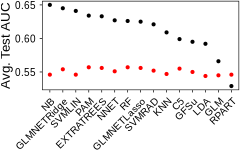

In [32]:
# TEST SET: AVG AUC AFTER SHUFFLE PHENOTYPES
plot_name = "model_test_shuffle_auc"

plot_me <- ggplot(merged_data %>% arrange(-avg_test_auc_v0), aes(x = reorder(model, -avg_test_auc_v0))) +
    geom_point(aes(y = avg_test_auc_v2, color = "v2"), size = 0.5) +
    geom_point(aes(y = avg_test_auc_v0, color = "v0"), size = 0.5) +
    labs(title = NULL,
             x = NULL,
             y = "Avg. Test AUC",
             color = "Phenotypes") +
    theme_cfrna_paper() +
    scale_y_continuous(breaks = seq(0, 1, by = 0.05)) +
    scale_color_manual(values = c("v2" = "red", "v0" = "black")) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_2/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)